# Feature extraction

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import librosa
import librosa.display
import ipywidgets as widgets
from IPython.display import display
from IPython.display import Audio
from scipy.fft import dct
import matplotlib.pyplot as plt

## <font color="orange"> Read and extract features from filenames <font>

In [5]:
folder = Path("../data/wav/")
mapping_dict = {
    "03": ["male", 31],
    "08": ["female", 34],
    "09": ["female", 21],
    "10": ["male", 32],
    "11": ["male", 26],
    "12": ["male", 30],
    "13": ["female", 32],
    "14": ["female", 35],
    "15": ["male", 25],
    "16": ["female", 31],
}
emotion_map = {
    "W": "anger", "L": "boredom", "E": "disgust", "A": "fear",
    "F": "happiness", "T": "sadness", "N": "neutral",
}
rows = []
for file in folder.glob("*.wav"):
    row = {
        "filename": file.name,
        "gender": mapping_dict[file.name[0:2]][0],
        "age": mapping_dict[file.name[0:2]][1],
        "emotion": emotion_map[file.name[5]],
    }
    rows.append(row)

df = pd.DataFrame(rows)
df


,filename,gender,age,emotion
0,03b09La.wav,male,31,boredom
1,08b10Fd.wav,female,34,happiness
2,08a07Fd.wav,female,34,happiness
3,11a01Wc.wav,male,26,anger
4,11a05Ad.wav,male,26,fear
...,...,...,...,...
530,14a01Ac.wav,female,35,fear
531,16a05La.wav,female,31,boredom
532,14a07Ld.wav,female,35,boredom
533,11a01Aa.wav,male,26,fear


## <font color="orange"> MFCCs extraction <font>

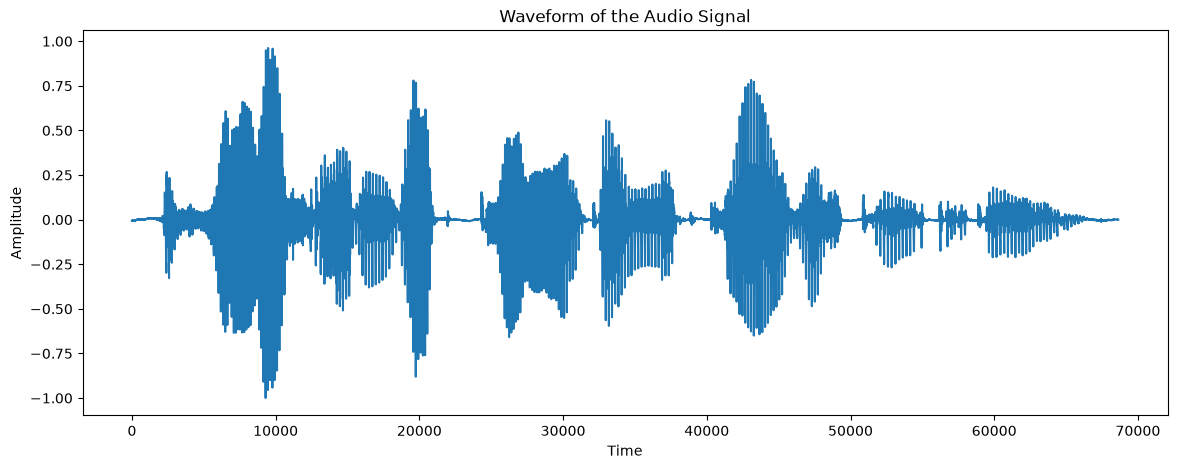

In [3]:
y, sr = librosa.load(folder / df["filename"][0])

# Plot the waveform
plt.figure(figsize=(14, 5))
plt.plot(y)
plt.title('Waveform of the Audio Signal')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.show()

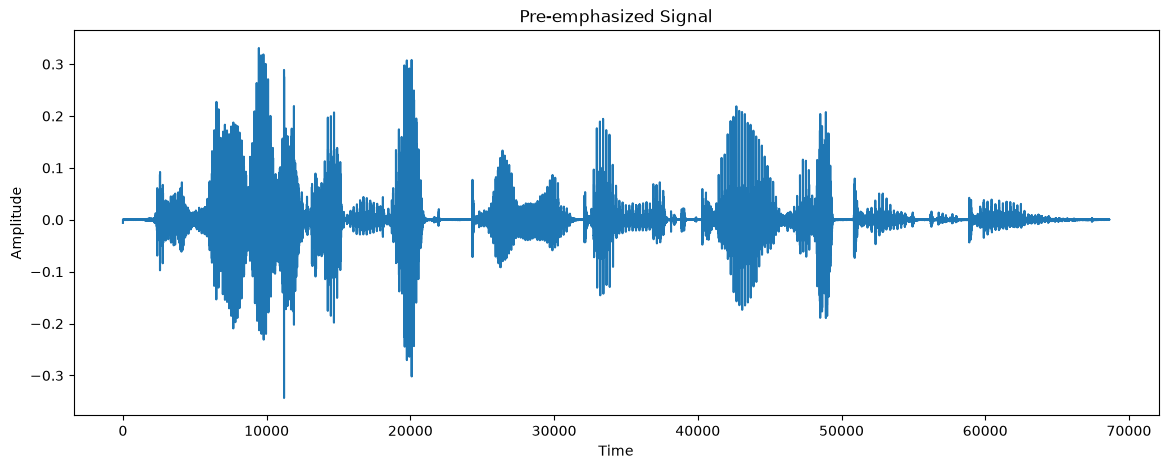

In [4]:
# Apply pre-emphasis filter
pre_emphasis = 0.97
y_preemphasized = np.append(y[0], y[1:] - pre_emphasis * y[:-1])

# Plot the pre-emphasized signal
plt.figure(figsize=(14, 5))
plt.plot(y_preemphasized)
plt.title('Pre-emphasized Signal')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.show()